# TP final IA II - Paso 1 (versión 2): etiquetas del Mapa Nacional de Cultivos del INTA, 6 campañas

Este notebook arma los mapas de etiquetas que usa el notebook 02. Respecto de la versión 1:
- **6 campañas en vez de 2:** de 2019/20 a 2024/25. La 2018/19 queda afuera porque no tiene mapa de invierno, y sin él no se puede separar la soja de 1ra de la de 2da.
- **La leyenda de invierno se traduce año por año.** Los códigos cambian entre campañas (ver la tabla de abajo): si se usara la misma tabla para todas, las sojas de 2019/20 y 2020/21 quedarían mal etiquetadas sin que nada falle.
- **Clase "Otros"**, para que el modelo sirva en un campo real: un lote de girasol o una pastura ya no se fuerza a ser maíz o soja.
- **Controles automáticos:** si los códigos del archivo no coinciden con la leyenda, el notebook se detiene.

### Pasos
1. Baja de Zenodo el mapa de invierno y el de verano de cada campaña, al disco temporal de Colab (no ocupan lugar en tu Drive).
2. Recorta la zona núcleo alrededor de Rosario.
3. Cruza invierno con verano para separar las sojas.
4. Guarda en Drive un GeoTIFF de etiquetas por campaña, en `datos_inta/v2/` (los de la versión 1 no se tocan).

### Etiquetas finales

| Valor | Clase | De dónde sale |
|---|---|---|
| 0 | Maíz | Verano = maíz (en 2024/25 también el verdeo de maíz) |
| 1 | Soja 1ra | Verano = soja **y** invierno = barbecho |
| 2 | Soja 2da | Verano = soja **y** invierno = cereal de invierno, arveja o garbanzo |
| 3 | Otros cultivos | Verano = girasol, sorgo, maní, poroto, etc. |
| 4 | No agrícola | Verano = barbecho o no agrícola (pastizales, pasturas, montes) |
| 255 | Se ignora | Todo lo demás, y la soja con un invierno dudoso (cultivo de cobertura, no agrícola) |

El notebook 02 junta las clases 3 y 4 en una sola, **"Otros"**, mitad de cada una. Se guardan separadas por si después conviene tratarlas distinto.

### Códigos del INTA por campaña (Tablas 1 y 2 de cada informe)

**Verano: iguales en las 6 campañas.** 10 maíz, 11 soja, 12 girasol, 13 poroto, 14 caña de azúcar, 15 algodón, 16 maní, 17 arroz, 18 sorgo, 19 girasol seguido de otro cultivo, 21 barbecho, 22 no agrícola; desde 2020/21 también 26 papa y 28 verdeo de sorgo; desde 2022/23, 30 tabaco. **Novedad de 2024/25: el código 27, verdeo de maíz** (maíz para pastoreo), que en los años anteriores venía incluido en maíz. Se suma a maíz para que la clase signifique lo mismo en todos los años y coincida con la superficie sembrada del MAGyP, que también lo incluye.

**Invierno: cambian.**

| Clase de invierno | 2019/20 | 2020/21 | 2021/22 a 2024/25 |
|---|---|---|---|
| Cereales de invierno (trigo, cebada, avena, centeno, verdeos) | **0** | **0** | 16 |
| Barbecho (sin cultivo de invierno) | **17** | 18 | 18 |
| Garbanzo | 6 (junto con cártamo) | 6 | 6 |
| Arveja | - | 24 | 24 |
| Otros cultivos / cobertura | - | - | 17 |
| Caña de azúcar | **18** | 19 | 19 |
| No agrícola | **19** | 20 | 20 |

**Calidad de las etiquetas.** Exactitud general del mapa de verano en las zonas del estudio (Tabla 6 de cada informe):

| Campaña | Zona VI (Núcleo Norte) | Zona VII (Núcleo Sur) |
|---|---|---|
| 2019/20 | 0,95 | 0,90 |
| 2020/21 | 0,94 | 0,91 |
| 2021/22 | 0,89 | 0,92 |
| 2022/23 | 0,86 | 0,89 |
| 2023/24 | 0,93 | 0,93 |
| 2024/25 | 0,89 | 0,91 |

2019/20 a 2021/22 se hicieron solo con Landsat (30 m); desde 2022/23, con Landsat y Sentinel-2. La campaña con más error es la de la sequía (2022/23).

**Si Colab se corta:** volvé a ejecutar todo. Las campañas que ya están en `datos_inta/v2/` no se vuelven a procesar. Las etiquetas se escriben primero en el disco de Colab y después se copian a Drive; si la conexión con Drive se cae (pasa en celdas largas), el notebook vuelve a montarlo solo y reintenta.

In [3]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE   = '/content/drive/MyDrive/TP_final_IA2'
    CRUDOS = '/content/crudos'                       # disco temporal de Colab: los tif completos no pasan por Drive
    EN_COLAB = True
except ImportError:                                  # fuera de Colab
    BASE   = os.environ.get('TP_BASE', 'TP_final_IA2')
    CRUDOS = os.environ.get('TP_CRUDOS', 'crudos')
    EN_COLAB = False

CARPETA = f'{BASE}/datos_inta/v2'
LOCAL   = f'{CRUDOS}/etiquetas'                    # se escribe primero acá y después se copia a Drive
os.makedirs(CARPETA, exist_ok=True)
os.makedirs(LOCAL, exist_ok=True)

import shutil, time
def a_drive(origen, destino, intentos=4):
    # Copia a Drive. Si la conexión con Drive se cayó (pasa en celdas largas), vuelve a montar y reintenta.
    for k in range(intentos):
        try:
            os.makedirs(os.path.dirname(destino), exist_ok=True)
            shutil.copy(origen, destino + '.tmp')
            os.replace(destino + '.tmp', destino)
            return
        except OSError as e:
            print(f'  Drive no respondió ({e.__class__.__name__}); se vuelve a montar y se reintenta...')
            if EN_COLAB:
                drive.mount('/content/drive', force_remount=True)
            time.sleep(5 * (k + 1))
    raise OSError(f'No se pudo guardar {destino} en Drive después de {intentos} intentos')

print('Etiquetas en', CARPETA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Etiquetas en /content/drive/MyDrive/TP_final_IA2/datos_inta/v2


In [4]:
%pip -q install rasterio

## 1. Parámetros y leyendas

In [5]:
BBOX = (-63.5, -34.2, -59.6, -31.5)     # oeste, sur, este, norte: sur de Santa Fe, sudeste de Córdoba, norte de Buenos Aires, oeste de Entre Ríos

# Verano: códigos iguales en las 6 campañas (Tabla 2 de cada informe)
VER_MAIZ           = [10]
VER_SOJA           = 11
VER_OTROS_CULTIVOS = [12, 13, 15, 16, 17, 18, 19, 26, 28, 30]   # girasol, poroto, algodón, maní, arroz, sorgo, girasol-CV, papa, verdeo de sorgo, tabaco
VER_NO_AGRICOLA    = [21, 22]                                   # barbecho de verano y no agrícola. La caña de azúcar (14) queda afuera

# Invierno: cambia según la campaña (Tabla 1 de cada informe)
LEY_INV_2019 = {0: 'Cereales de invierno', 6: 'Garbanzo y cártamo', 17: 'Barbecho', 18: 'Caña de azúcar', 19: 'No agrícola'}
LEY_INV_2020 = {0: 'Cereales de invierno', 6: 'Garbanzo', 24: 'Arveja', 18: 'Barbecho', 19: 'Caña de azúcar', 20: 'No agrícola'}
LEY_INV_2021 = {16: 'Cereales de invierno', 6: 'Garbanzo', 24: 'Arveja', 26: 'Papa', 17: 'Otros cultivos / cobertura',
                18: 'Barbecho', 19: 'Caña de azúcar', 20: 'No agrícola'}

CAMPANAS = {
    '2019_20': {'zenodo': '8286310',  'verano': 'mnc-verano-2020.tif', 'invierno': 'mnc-invierno-2019.tif',
                'inv_grano': [0, 6],      'inv_barbecho': [17], 'extra_maiz': [],   'leyenda_inv': LEY_INV_2019},
    '2020_21': {'zenodo': '8286318',  'verano': 'verano-2021.tif',     'invierno': 'invierno-2020.tif',
                'inv_grano': [0, 6, 24],  'inv_barbecho': [18], 'extra_maiz': [],   'leyenda_inv': LEY_INV_2020},
    '2021_22': {'zenodo': '8284081',  'verano': 'MNC_verano2022.tif',  'invierno': 'MNC_invierno2021.tif',
                'inv_grano': [16, 6, 24], 'inv_barbecho': [18], 'extra_maiz': [],   'leyenda_inv': LEY_INV_2021},
    '2022_23': {'zenodo': '10103323', 'verano': 'MNC_verano-2023.tif', 'invierno': 'MNC_invierno2022.tif',
                'inv_grano': [16, 6, 24], 'inv_barbecho': [18], 'extra_maiz': [],   'leyenda_inv': LEY_INV_2021},
    '2023_24': {'zenodo': '13984185', 'verano': 'MNC_verano-2024.tif', 'invierno': 'MNC_invierno2023.tif',
                'inv_grano': [16, 6, 24], 'inv_barbecho': [18], 'extra_maiz': [],   'leyenda_inv': LEY_INV_2021},
    '2024_25': {'zenodo': '17652712', 'verano': 'MNC_ver25.tif',       'invierno': 'MNC_inv24.tif',
                'inv_grano': [16, 6, 24], 'inv_barbecho': [18], 'extra_maiz': [27], 'leyenda_inv': LEY_INV_2021},
}

NOMBRES = {0: 'Maíz', 1: 'Soja 1ra', 2: 'Soja 2da', 3: 'Otros cultivos', 4: 'No agrícola'}
MIN_SOJA_CLASIFICADA = 0.85    # control: si los códigos estuvieran mal, casi nada de la soja caería sobre barbecho o grano (en la prueba con códigos equivocados dio 0 %)

def ruta_etiqueta(camp):
    return f'{CARPETA}/etiquetas_{camp}.tif'

## 2. Descarga desde Zenodo

Unos 2 GB en total, al disco temporal de Colab (entre 20 y 40 minutos). Solo se bajan las campañas que todavía no tienen su etiqueta en Drive. Si un archivo no se encuentra, el mensaje muestra el link del registro para revisar el nombre.

In [6]:
import urllib.request, urllib.error, time

def bajar(rec, nombre):
    destino = f'{CRUDOS}/{nombre}'
    if os.path.exists(destino):
        return destino
    url = f'https://zenodo.org/records/{rec}/files/{nombre}?download=1'
    t0 = time.time()
    try:
        urllib.request.urlretrieve(url, destino + '.parcial')     # se renombra al terminar: un corte no deja un archivo roto
    except urllib.error.HTTPError as e:
        raise RuntimeError(f'No se pudo bajar {nombre} ({e.code}). Revisá el nombre en https://zenodo.org/records/{rec}') from e
    os.rename(destino + '.parcial', destino)
    print(f'  {nombre}: {os.path.getsize(destino) / 1e6:.0f} MB en {time.time() - t0:.0f} s')
    return destino

for camp, cfg in CAMPANAS.items():
    if os.path.exists(ruta_etiqueta(camp)):
        print(f'{camp}: la etiqueta ya está en Drive, no hace falta bajar nada')
        continue
    print(f'{camp}: bajando de Zenodo (registro {cfg["zenodo"]})')
    for clave in ('verano', 'invierno'):
        bajar(cfg['zenodo'], cfg[clave])

2019_20: la etiqueta ya está en Drive, no hace falta bajar nada
2020_21: bajando de Zenodo (registro 8286318)
  verano-2021.tif: 131 MB en 35 s
  invierno-2020.tif: 112 MB en 163 s
2021_22: bajando de Zenodo (registro 8284081)
  MNC_verano2022.tif: 127 MB en 187 s
  MNC_invierno2021.tif: 111 MB en 33 s
2022_23: bajando de Zenodo (registro 10103323)
  MNC_verano-2023.tif: 200 MB en 49 s
  MNC_invierno2022.tif: 167 MB en 98 s
2023_24: bajando de Zenodo (registro 13984185)
  MNC_verano-2024.tif: 201 MB en 11 s
  MNC_invierno2023.tif: 178 MB en 10 s
2024_25: bajando de Zenodo (registro 17652712)
  MNC_ver25.tif: 193 MB en 11 s
  MNC_inv24.tif: 174 MB en 68 s


## 3. Recorte, cruce invierno-verano y controles

Para cada campaña:
1. Se recorta la zona de los dos mapas. Si invierno y verano no están en la misma grilla, se lleva el de invierno a la grilla del de verano (vecino más cercano: los códigos no se promedian).
2. Se muestra **qué había en invierno debajo de la soja**, con los nombres de la leyenda de ese año. Es el control más importante: si los códigos estuvieran mal, la mayor parte de la soja caería en clases sin sentido.
3. **Control automático:** al menos el 85 % de la soja tiene que caer sobre barbecho o sobre un grano de invierno. Si los códigos estuvieran mal, ese número sería cercano a 0 % y el notebook se detiene. Entre 85 y 95 % solo avisa: es soja sobre un invierno dudoso (por ejemplo, en 2020/21 el mapa no tenía la clase de cultivos de cobertura y parte de esos lotes figuran como no agrícola) y se descarta.
4. Se arman y se guardan las etiquetas.

In [7]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds, reproject, Resampling

def recortar(ruta):
    with rasterio.open(ruta) as src:
        b = transform_bounds('EPSG:4326', src.crs, *BBOX)
        win = from_bounds(*b, transform=src.transform).round_offsets().round_lengths()
        win = win.intersection(Window(0, 0, src.width, src.height))
        data = src.read(1, window=win)
        perfil = src.profile.copy()
        perfil.update(height=data.shape[0], width=data.shape[1], transform=src.window_transform(win), count=1,
                      dtype='uint8', nodata=255, compress='deflate', tiled=True, blockxsize=256, blockysize=256)
    return data, perfil

def a_grilla(data, perfil_origen, perfil_destino):
    # lleva un mapa de códigos a otra grilla sin mezclar códigos (vecino más cercano)
    out = np.full((perfil_destino['height'], perfil_destino['width']), 255, dtype=data.dtype)
    reproject(data, out, src_transform=perfil_origen['transform'], src_crs=perfil_origen['crs'],
              dst_transform=perfil_destino['transform'], dst_crs=perfil_destino['crs'],
              resampling=Resampling.nearest, src_nodata=None, dst_nodata=255)
    return out

def procesar(camp, cfg):
    v, perfil = recortar(f'{CRUDOS}/{cfg["verano"]}')
    i, perfil_i = recortar(f'{CRUDOS}/{cfg["invierno"]}')
    if v.shape != i.shape or perfil['transform'] != perfil_i['transform']:
        print('  invierno y verano en grillas distintas: se lleva invierno a la grilla de verano')
        i = a_grilla(i, perfil_i, perfil)

    lat_media = (BBOX[1] + BBOX[3]) / 2
    res_x, res_y = abs(perfil['transform'].a), abs(perfil['transform'].e)
    if perfil['crs'] and perfil['crs'].is_geographic:     # pixel en grados -> hectáreas a la latitud de la zona
        pixel_ha = (res_x * 111320 * np.cos(np.radians(lat_media))) * (res_y * 110570) / 1e4
    else:
        pixel_ha = res_x * res_y / 1e4

    maiz = np.isin(v, VER_MAIZ + cfg['extra_maiz'])
    soja = v == VER_SOJA
    assert soja.sum() > 0 and maiz.sum() > 0, f'{camp}: no hay maíz o soja en el recorte. ¿Está bien el archivo de verano?'

    # Qué había en invierno debajo de la soja
    cod, n = np.unique(i[soja], return_counts=True)
    print(f'  Invierno debajo de la soja:')
    for c, k in sorted(zip(cod, n), key=lambda x: -x[1]):
        if k / soja.sum() >= 0.001:
            print(f'    {int(c):>3} {cfg["leyenda_inv"].get(int(c), "(no está en la leyenda)"):28s} {100 * k / soja.sum():5.1f} %')

    barbecho = np.isin(i, cfg['inv_barbecho'])
    grano = np.isin(i, cfg['inv_grano'])
    cubierta = (soja & (barbecho | grano)).sum() / soja.sum()
    frac_2da = (soja & grano).sum() / soja.sum()
    assert cubierta >= MIN_SOJA_CLASIFICADA, (
        f'{camp}: solo el {100 * cubierta:.0f} % de la soja cae sobre barbecho o grano de invierno. '
        f'Revisá los códigos de invierno de esta campaña contra la Tabla 1 de su informe.')
    if cubierta < 0.95:
        print(f'  Aviso: el {100 * (1 - cubierta):.1f} % de la soja tiene un invierno dudoso (no agrícola, cobertura) y se descarta. '
              f'Los códigos están bien; solo se pierde ese porcentaje.')
    if not 0.05 <= frac_2da <= 0.6:
        print(f'  ATENCIÓN: la soja de 2da es el {100 * frac_2da:.0f} % de la soja; lo esperable en la zona es entre 15 y 40 %')
    if cfg['extra_maiz']:
        print(f'  Verdeo de maíz sumado a maíz: {100 * np.isin(v, cfg["extra_maiz"]).sum() / maiz.sum():.1f} % del maíz')

    etiqueta = np.full(v.shape, 255, dtype='uint8')
    etiqueta[np.isin(v, VER_OTROS_CULTIVOS)] = 3
    etiqueta[np.isin(v, VER_NO_AGRICOLA)] = 4
    etiqueta[maiz] = 0
    etiqueta[soja & barbecho] = 1
    etiqueta[soja & grano] = 2              # la soja con otro invierno (cobertura, no agrícola) queda en 255

    local = f'{LOCAL}/etiquetas_{camp}.tif'
    with rasterio.open(local, 'w', **perfil) as dst:
        dst.write(etiqueta, 1)
    a_drive(local, ruta_etiqueta(camp))

    fila = {'campaña': camp}
    for k, nombre in NOMBRES.items():
        fila[nombre] = round((etiqueta == k).sum() * pixel_ha / 1000)        # miles de ha
    fila['% soja descartada'] = round(100 * (1 - cubierta), 1)
    fila['% soja 2da / soja'] = round(100 * frac_2da, 1)
    return fila

import json
RESUMEN = f'{CARPETA}/resumen_etiquetas.json'
resumen = json.load(open(RESUMEN)) if os.path.exists(RESUMEN) else {}
def guardar_resumen():
    json.dump(resumen, open(f'{LOCAL}/resumen_etiquetas.json', 'w'), indent=1)
    a_drive(f'{LOCAL}/resumen_etiquetas.json', RESUMEN)
for camp, cfg in CAMPANAS.items():
    if os.path.exists(ruta_etiqueta(camp)) and camp in resumen:
        print(f'{camp}: ya procesada')
        continue
    print(f'\n{camp}')
    resumen[camp] = procesar(camp, cfg)
    guardar_resumen()
    for clave in ('verano', 'invierno'):               # libera el disco temporal
        if os.path.exists(f'{CRUDOS}/{cfg[clave]}'):
            os.remove(f'{CRUDOS}/{cfg[clave]}')
print('\nListo')

2019_20: ya procesada

2020_21
  Invierno debajo de la soja:
     18 Barbecho                      64.2 %
      0 Cereales de invierno          29.2 %
     20 No agrícola                    6.5 %
     24 Arveja                         0.1 %
  Aviso: el 6.5 % de la soja tiene un invierno dudoso (no agrícola, cobertura) y se descarta. Los códigos están bien; solo se pierde ese porcentaje.

2021_22
  Invierno debajo de la soja:
     18 Barbecho                      63.7 %
     16 Cereales de invierno          35.7 %
     24 Arveja                         0.4 %

2022_23
  Invierno debajo de la soja:
     18 Barbecho                      71.5 %
     16 Cereales de invierno          28.4 %
     20 No agrícola                    0.1 %

2023_24
  Invierno debajo de la soja:
     18 Barbecho                      71.5 %
     16 Cereales de invierno          28.0 %
     24 Arveja                         0.3 %

2024_25
  Invierno debajo de la soja:
     18 Barbecho                      68.2 %
    

## 4. Resumen de las 6 campañas

Superficie de cada clase en la zona, en **miles de hectáreas**. Cosas para mirar:
- **Maíz y soja deberían moverse como en las estadísticas.** En la sequía de 2022/23 se sembró parecido, pero cambia la proporción de soja de 2da según cuánto trigo hubo ese invierno.
- **La soja de 2da tiene que estar entre el 15 y el 40 % de la soja.** Si un año da cerca de 0 % o más de la mitad, los códigos de invierno de ese año están mal.
- **La soja descartada tiene que ser chica** (menos de 15 %; si no, el notebook ya se habría detenido).

Superficie por clase (miles de ha) y controles de la soja:

         Maíz  Soja 1ra  Soja 2da  Otros cultivos  No agrícola  % soja descartada  % soja 2da / soja
campaña                                                                                             
2019_20  1674      3052      1629              14         2987                0.2               34.7
2020_21  1830      3072      1406              51         2609                6.5               29.4
2021_22  2021      2653      1506              40         3054                0.1               36.2
2022_23  1750      2924      1162               8         3352                0.1               28.4
2023_24  2040      3053      1208              99         2842                0.2               28.3
2024_25  1210      3448      1596             198         2798                0.2               31.6


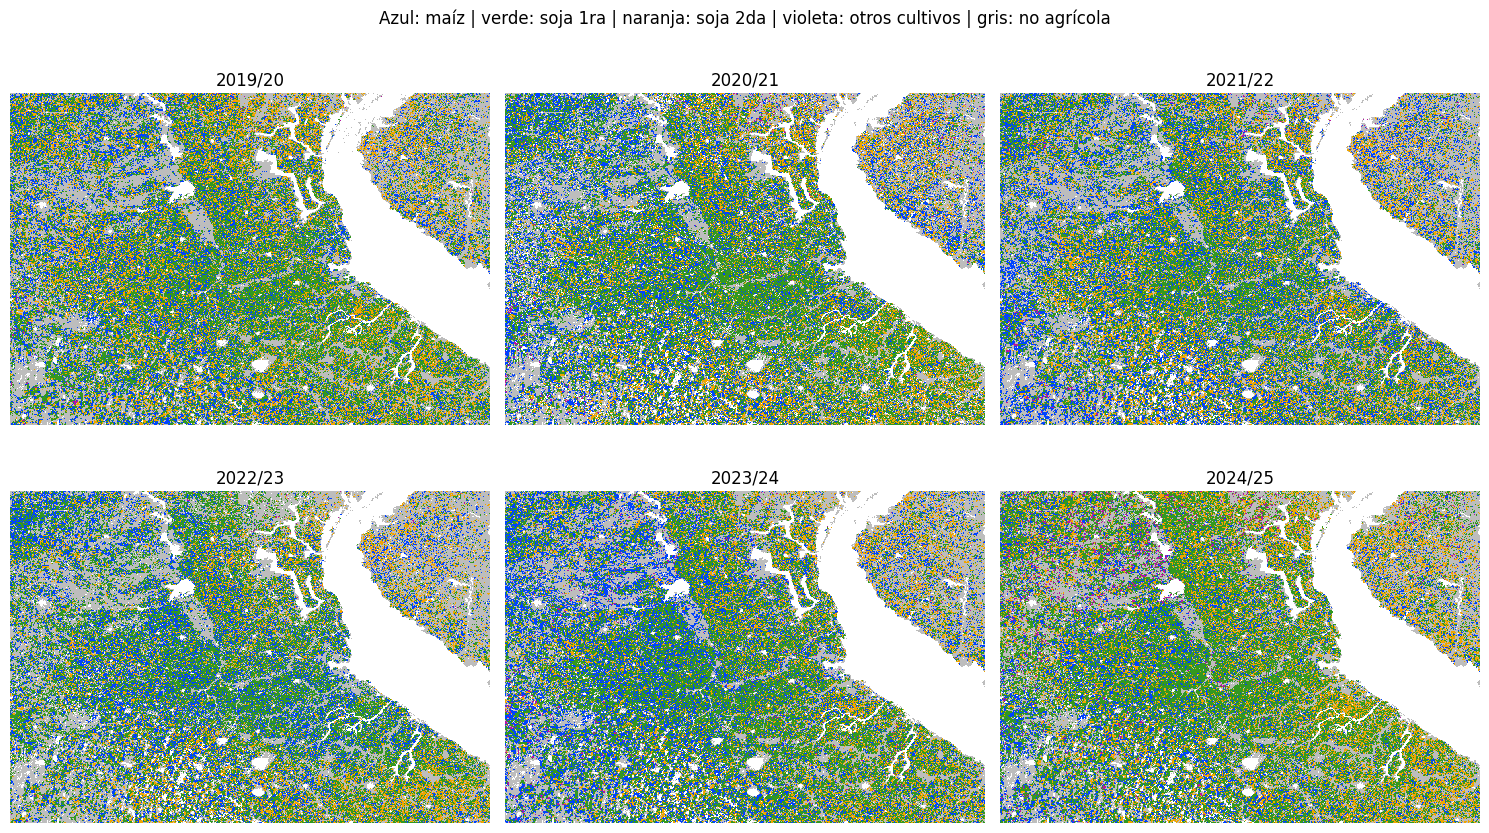

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

tabla = pd.DataFrame(list(resumen.values())).set_index('campaña').loc[list(CAMPANAS)]
print('Superficie por clase (miles de ha) y controles de la soja:\n')
print(tabla.to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
cmap = ListedColormap(['#0042ff', '#339820', '#f0a500', '#b5179e', '#bdbdbd'])
for ax, camp in zip(axes.ravel(), CAMPANAS):
    ruta = f'{LOCAL}/etiquetas_{camp}.tif' if os.path.exists(f'{LOCAL}/etiquetas_{camp}.tif') else ruta_etiqueta(camp)
    with rasterio.open(ruta) as src:
        e = src.read(1)[::12, ::12].astype(float)
    e[e == 255] = np.nan
    ax.imshow(e, cmap=cmap, vmin=-0.5, vmax=4.5, interpolation='nearest')
    ax.set_title(camp.replace('_', '/')); ax.axis('off')
fig.suptitle('Azul: maíz | verde: soja 1ra | naranja: soja 2da | violeta: otros cultivos | gris: no agrícola')
plt.tight_layout(); plt.show()

## Siguiente paso

Los seis `etiquetas_<campaña>.tif` quedan en `MyDrive/TP_final_IA2/datos_inta/v2/`. El notebook 02 (versión 2) los lee de ahí, sortea los puntos y baja las imágenes de Sentinel-2.

Para el informe: los códigos de invierno de cada año se tomaron de la Tabla 1 de su informe y se verificaron contra los archivos con el control de la sección 3.